In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

In [5]:
df = pd.read_csv('Grocery.csv')
df.head()

,Product,Category,Price,Quantity
0,Bread,Food,20,2
1,Milk,Food,60,5
2,Biscuit,Food,20,2
3,Bourn-Vita,Food,70,1
4,Maggi,Food,20,5


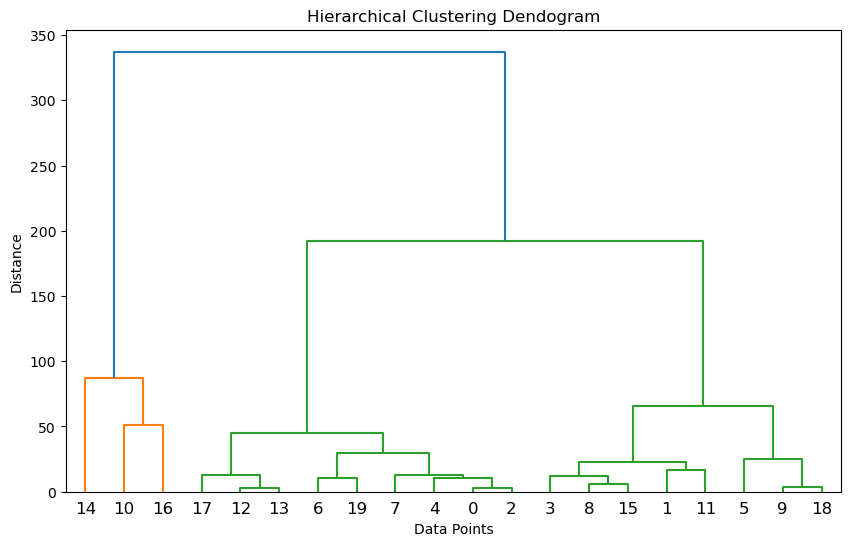

Cluster Label: 
[2 1 2 1 2 1 2 2 1 1 0 1 2 2 0 1 0 2 1 2]


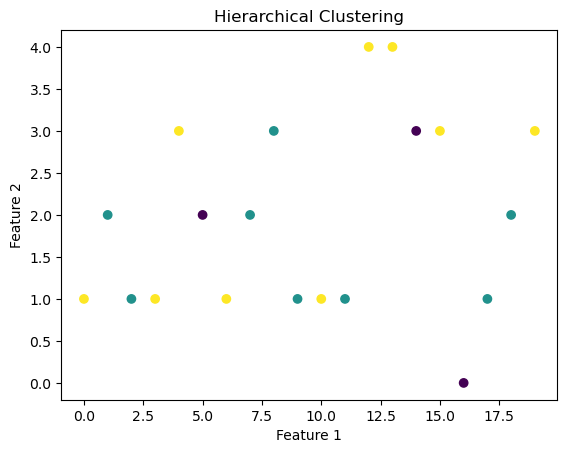

In [6]:
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = LabelEncoder().fit_transform(df[col])

linked = linkage(
    df,
    method = 'ward'
)

plt.figure(figsize = (10, 6))
dendrogram(linked)

plt.title('Hierarchical Clustering Dendogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

model = AgglomerativeClustering(
    n_clusters = 3
)

clusters = model.fit_predict(df)

print('Cluster Label: ')
print(clusters)

df['Cluster'] = clusters
plt.scatter(
    df.iloc[:, 0],
    df.iloc[:, 1],
    c = clusters
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Hierarchical Clustering')
plt.show()